# 04 · 环与圆盘：拓扑特征是否提供额外信息？

**可运行实验**：固定种子生成独立点云，比较距离统计、H₁ 持续特征、二者拼接。所有模型使用同样的训练/测试划分与最近质心分类器，标准化只拟合训练集。没有调参步骤，测试集只用于最后报告。

**理论边界**：这是一批有限合成数据的结果，不证明 TDA 在一般 AI 任务上有效，也不把实验当作稳定性定理的证明。采样点云的短条全部保留；所有有限 H₁ 条参与特征计算。

依赖 NumPy、Matplotlib、GUDHI 3.11.0（`requirements-validation.txt`）。无网络或外部数据。条形码的过滤参数为球半径 ε，边距离阈值为 2ε。代码 MIT，原创说明 CC BY 4.0。

In [1]:
import numpy as np
import gudhi
import matplotlib.pyplot as plt
SEED=20261012
rng=np.random.default_rng(SEED)

def cloud(label,n=24):
    theta=rng.uniform(0,2*np.pi,n)
    radius=(1+rng.normal(0,0.04,n)) if label==1 else np.sqrt(rng.uniform(0,1,n))
    points=np.column_stack([radius*np.cos(theta),radius*np.sin(theta)])
    return points*rng.uniform(0.8,1.2)+rng.normal(0,0.3,(1,2))

def features(points):
    distances=np.linalg.norm(points[:,None,:]-points[None,:,:],axis=2)
    pairwise=distances[np.triu_indices(len(points),1)]
    geom=np.array([pairwise.mean(),pairwise.std(),*np.quantile(pairwise,[0.1,0.5,0.9])])
    st=gudhi.RipsComplex(distance_matrix=distances.tolist()).create_simplex_tree(max_dimension=2)
    st.persistence(homology_coeff_field=2,min_persistence=0,persistence_dim_max=True)
    bars=st.persistence_intervals_in_dimension(1)/2 # edge scale -> radius scale
    assert bars.shape[1]==2
    assert np.isfinite(bars).all() # full graph with all triangles kills H1
    assert np.all(bars[:,1]>bars[:,0])
    life=bars[:,1]-bars[:,0]
    topo=np.array([life.max(initial=0),life.sum(),np.square(life).sum()])
    return geom,topo

labels=np.repeat([0,1],48)
clouds=[cloud(int(y)) for y in labels]
all_features=[features(p) for p in clouds]
geometry=np.array([f[0] for f in all_features])
topology=np.array([f[1] for f in all_features])
train=[]; test=[]
for y in [0,1]:
    indices=rng.permutation(np.flatnonzero(labels==y))
    train.extend(indices[:32]); test.extend(indices[32:])
train=np.array(train); test=np.array(test)
assert len(train)==64 and len(test)==32
assert not set(train)&set(test)
assert set(train)|set(test)==set(range(96))
print('Seed:',SEED,'; GUDHI:',gudhi.__version__,'; train/test:',len(train),len(test))


Seed: 20261012 ; GUDHI: 3.11.0 ; train/test: 64 32


In [2]:
def fit_centroids(x,y):
    mean=x.mean(axis=0); scale=x.std(axis=0)
    scale=np.where(scale==0,1,scale)
    z=(x-mean)/scale
    centroids=np.array([z[y==c].mean(axis=0) for c in [0,1]])
    return mean,scale,centroids

def predict(model,x):
    mean,scale,centroids=model
    z=(x-mean)/scale
    return np.square(z[:,None,:]-centroids[None,:,:]).sum(axis=2).argmin(axis=1)

designs={'Geometry':geometry,'Topology':topology,'Combined':np.column_stack([geometry,topology])}
results={}
for name,x in designs.items():
    model=fit_centroids(x[train],labels[train])
    assert np.array_equal(model[0],x[train].mean(axis=0))
    assert np.array_equal(predict(model,x[test]),predict(model,x[test].copy()))
    pred=predict(model,x[test]); truth=labels[test]
    confusion=np.array([[np.sum((truth==a)&(pred==b)) for b in [0,1]] for a in [0,1]])
    assert confusion.sum()==len(test)
    accuracy=float(np.mean(pred==truth))
    results[name]={'accuracy':accuracy,'confusion':confusion.tolist(),'features':x.shape[1]}
    print(name,results[name])
assert all(0<=r['accuracy']<=1 for r in results.values())
# No accuracy floor: predictive success is an observed result, not an assertion to tune toward.


Geometry {'accuracy': 0.9375, 'confusion': [[16, 0], [2, 14]], 'features': 5}
Topology {'accuracy': 0.96875, 'confusion': [[16, 0], [1, 15]], 'features': 3}
Combined {'accuracy': 0.96875, 'confusion': [[16, 0], [1, 15]], 'features': 8}


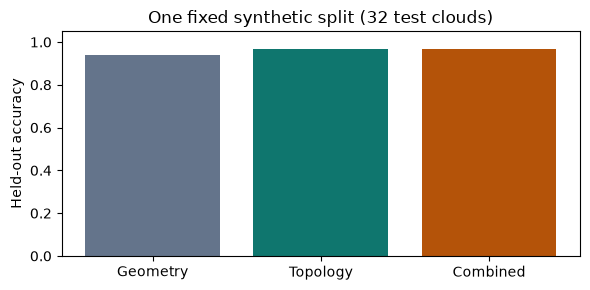

Topology minus geometry accuracy on this split: 0.03125
This finite result is not a general advantage claim; no test-based parameter selection was performed.


In [3]:
fig,ax=plt.subplots(figsize=(6,3))
ax.bar(list(results),[r['accuracy'] for r in results.values()],color=['#64748b','#0f766e','#b45309'])
ax.set_ylim(0,1.05); ax.set_ylabel('Held-out accuracy'); ax.set_title('One fixed synthetic split (32 test clouds)')
plt.tight_layout(); plt.show()
best_geo=results['Geometry']['accuracy']; topo_acc=results['Topology']['accuracy']
print('Topology minus geometry accuracy on this split:',topo_acc-best_geo)
print('This finite result is not a general advantage claim; no test-based parameter selection was performed.')


## 解释结果与练习

必须同时读取三组准确率和混淆矩阵。若拓扑特征没有超过基线，应如实保留结果；32 个测试点云不足以支持普遍优势。没有给模型增加复杂度来追求更好看数字。

1. 在运行前登记新的独立种子与噪声级别，报告每个条件的全部结果，不只挑最好一次。
2. 若拟选择景观网格或核宽，如何增加验证集？提示：最终测试集保持隔离。
3. 把半径参数误当边长参数会怎样改变三个拓扑特征？提示：寿命一次项缩放为 1/2，平方和为 1/4。
4. 将同一原始点云的噪声副本分到训练和测试会有什么问题？提示：按原始物体分组。

参考：Bubenik (JMLR 2015)；Adams et al. (JMLR 2017)；Chazal–Michel (2021)。理论推导见 A1–A2、R1–R2。